# 🧪 LAB: Clustering several real datasets

**Motivation**: This lab adopts three contrasting datasets to illustrate how clustering behaves under different real-world conditions—differences in scale, varying cluster separations, and high-dimensional gene expression data. You will put these concepts into practice by applying different clustering methods and evaluating how well they uncover structure in each dataset.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Kaitlin Luu, Natalie Schweickert, James Torgerson"

## Part 1: Clustering arrests by U.S. state (25 points)

The dataset below contains statistics for the 50 U.S. states on four variables recorded in 1973:

- Murder: Arrests for murder (per 100,000 residents)
- Assault: Arrests for assault (per 100,000 residents)
- UrbanPop: Percentage of urban population
- Rape: Arrests for rape (per 100,000 residents)

1. Perform hierarchical clustering using complete linkage and Euclidean distance. Plot the resulting dendrogram.

2. Cut the dendrogram at a height that produces three clusters. Which states belong to each cluster?

3. Repeat the hierarchical clustering, again using complete linkage and Euclidean distance, after scaling all variables to have a standard deviation equal to one.

4. Compare the two clustering solutions. What effect does scaling the variables have on the resulting dendrogram and cluster memberships?
In your opinion, should the variables be scaled in this case before computing inter-observation dissimilarities? Provide a justification for your answer.

In [21]:
import pandas as pd 
dat_1 = pd.read_csv("Lab08-part1_data.csv")
states = dat_1.state.to_list()
X = dat_1.drop(columns="state")
X.head() # This is the dataset to use

,Murder,Assault,UrbanPop,Rape
0,13.2,236,58,21.2
1,10.0,263,48,44.5
2,8.1,294,80,31.0
3,8.8,190,50,19.5
4,9.0,276,91,40.6


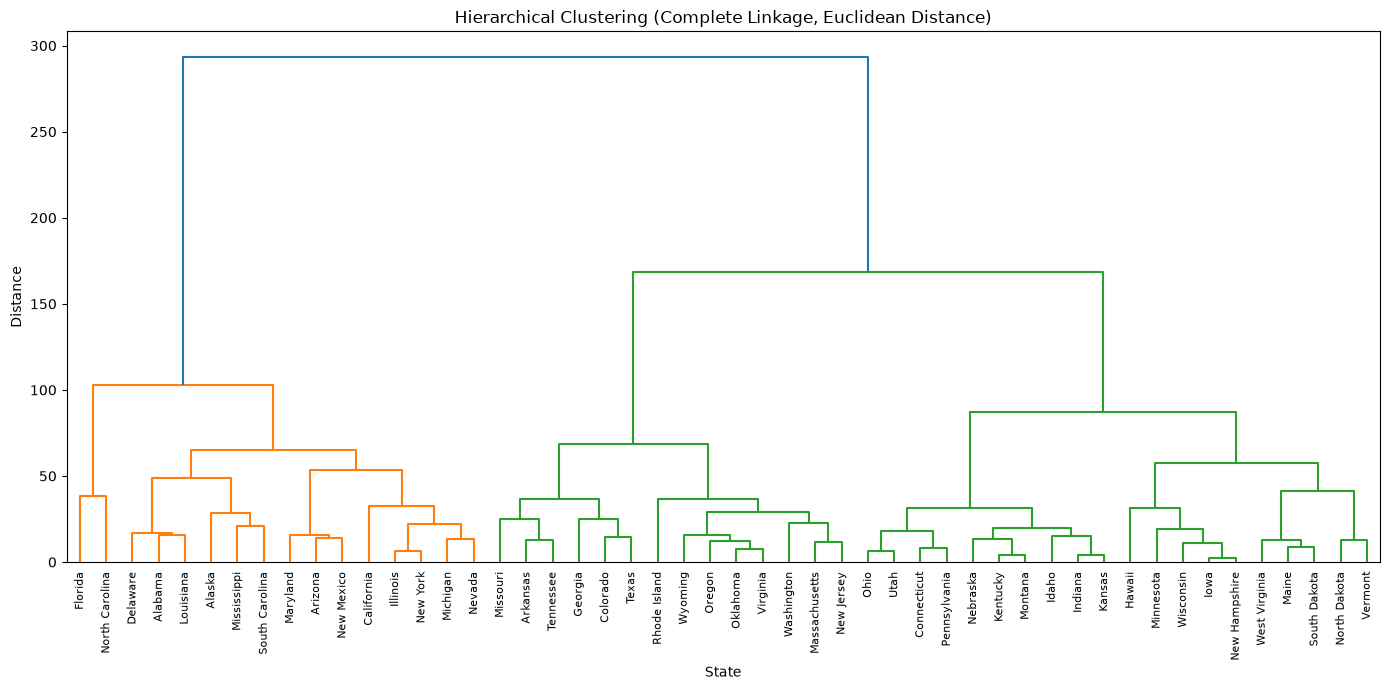

In [22]:
# Perform hierarchical clustering using complete linkage and Euclidean distance. Plot the resulting dendrogram.

# imports
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# linkage and Euclidean distances
Z = linkage(X, method="complete", metric="euclidean")

# plot the dendrogram
fig, ax = plt.subplots(figsize=(14, 7))
dendrogram(Z, labels=states, leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.set_title("Hierarchical Clustering (Complete Linkage, Euclidean Distance)")
ax.set_xlabel("State")
ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()

In [24]:
# Cut the dendrogram at a height that produces three clusters. Which states belong to each cluster?

# imports
from scipy.cluster.hierarchy import fcluster

# 3 clusters
labels = fcluster(Z, t=3, criterion="maxclust")

# print what states belong to each cluster
clusters = pd.DataFrame({"state": states, "cluster": labels})
for c in sorted(clusters["cluster"].unique()):
    members = clusters.loc[clusters["cluster"] == c, "state"].tolist()
    print(f"Cluster {c} ({len(members)} states): {', '.join(members)}")

Cluster 1 (16 states): Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina
Cluster 2 (14 states): Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming
Cluster 3 (20 states): Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin


0.0
1.0


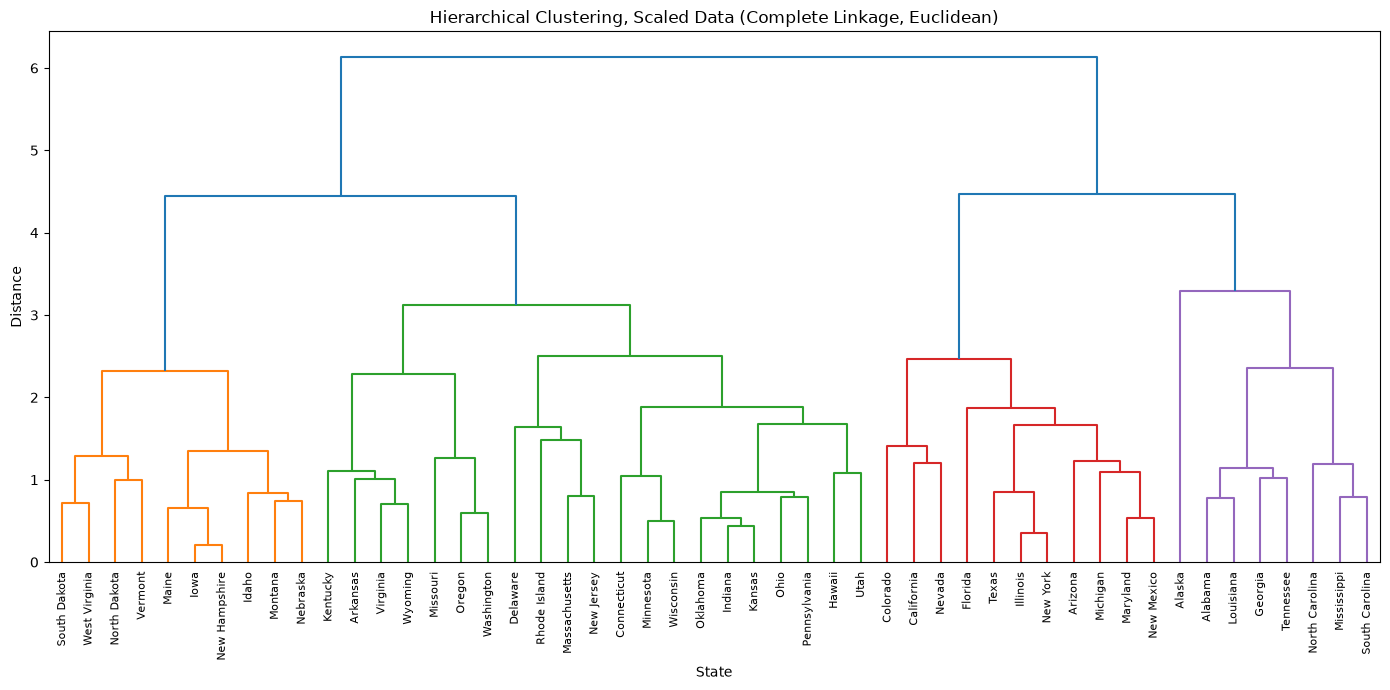

Cluster 1 (31 states): Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming
Cluster 2 (11 states): Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas
Cluster 3 (8 states): Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee


In [28]:
# Repeat the hierarchical clustering, again using complete linkage and Euclidean distance, after scaling all variables to have a standard deviation equal to one.

# import
from sklearn.preprocessing import StandardScaler

# scaling
X_scaled = StandardScaler().fit_transform(X)
# verify mean is 0 and std is 1
print(X_scaled.mean().round(6))
print(X_scaled.std())

# repeat
Z_scaled = linkage(X_scaled, method="complete", metric="euclidean")
fig, ax = plt.subplots(figsize=(14, 7))
dendrogram(Z_scaled, labels=states, leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.set_title("Hierarchical Clustering, Scaled Data (Complete Linkage, Euclidean)")
ax.set_xlabel("State")
ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()
labels_scaled = fcluster(Z_scaled, t=3, criterion="maxclust")
clusters_scaled = pd.DataFrame({"state": states, "cluster": labels_scaled})
for c in sorted(clusters_scaled["cluster"].unique()):
    members = clusters_scaled.loc[clusters_scaled["cluster"] == c, "state"].tolist()
    print(f"Cluster {c} ({len(members)} states): {', '.join(members)}")

In [26]:
# compare states in the clusters before and after scaling for analysis

# cluster before and after scaling
Z_raw = linkage(X, method="complete", metric="euclidean")
Z_scl = linkage(X_scaled, method="complete", metric="euclidean")

cut_raw = fcluster(Z_raw, t=3, criterion="maxclust")
cut_scl = fcluster(Z_scl, t=3, criterion="maxclust")

comp = pd.DataFrame({"state": states, "unscaled": cut_raw, "scaled": cut_scl})

# for each unscaled cluster, find the scaled cluster that holds most of its states
match = comp.groupby("unscaled")["scaled"].agg(lambda s: s.value_counts().idxmax())
comp["expected"] = comp["unscaled"].map(match)

# states that are not in the scaled cluster their original group mostly moved to
changed = comp[comp["scaled"] != comp["expected"]]

print(f"States that changed groups ({len(changed)}):")
for _, row in changed.iterrows():
    print(f"  {row['state']}: unscaled cluster {row['unscaled']} -> scaled cluster {row['scaled']}")

States that changed groups (11):
  Alabama: unscaled cluster 1 -> scaled cluster 3
  Alaska: unscaled cluster 1 -> scaled cluster 3
  Colorado: unscaled cluster 2 -> scaled cluster 2
  Delaware: unscaled cluster 1 -> scaled cluster 1
  Georgia: unscaled cluster 2 -> scaled cluster 3
  Louisiana: unscaled cluster 1 -> scaled cluster 3
  Mississippi: unscaled cluster 1 -> scaled cluster 3
  North Carolina: unscaled cluster 1 -> scaled cluster 3
  South Carolina: unscaled cluster 1 -> scaled cluster 3
  Tennessee: unscaled cluster 2 -> scaled cluster 3
  Texas: unscaled cluster 2 -> scaled cluster 2


Note: A state was counted as changing groups if it was not in the scaled cluster that most of its original unscaled cluster’s states moved to. Cluster numbers are arbitrary across runs, so matching numbers (e.g., Delaware, 1 → 1) don’t mean a state stayed in the same group (n = 11).

Questions: Compare the two clustering solutions. What effect does scaling the variables have on the resulting dendrogram and cluster memberships? In your opinion, should the variables be scaled in this case before computing inter-observation dissimilarities? Provide a justification for your answer.

The first clustering solution had 16 states in the first cluster group, 14 in the next, and 20 in the last, making the split of states relatively even. The second clustering solution, after scaling, has 31 states in the first cluster group, 11 in the next, and 8 in the last, making the split of states relatively uneven. 

For effects on the dendrogram and cluster membership, the two dendrograms have differnt height scales. The unscaled merge distances reach about 300, while scaled distances reach about 6. For cluster membership, 11 states changed groups.

I think the variables should be scaled before computing inter-observation dissimilarities becuase scaling the variables ensures every variable contributes equally to the dissimilarity matrix and the resulting dendrogram structure. In this dataset the 4 variables were measured in different units. Murder, Assault, and Rape were all per 100,000 residents but UrbanPop was a percentage. Euclidean distance adds squared differences across variables, so without scaling, the distances depend on those units and on each variable’s spread, not on how similar the states really are. Standardizing gives each variable a standard deviation of 1, so each contributes comparably to the dissimilarities. The trade-off is that the scaled three-cluster solution is lopsided (31/11/8), so the cut should be interpreted with that in mind.

## Part 2: Clustering, genomic data, and cancer (35 points)

Unsupervised techniques are often used to analyze genomic data. In particular, PCA and hierarchical clustering are popular tools.
You will apply these techniques to the dataset below, which consists of gene expression measurements for 64 cancer cell lines across 6,830 genes.

1. Perform hierarchical clustering of the data using complete, single, and average linkage. Use Euclidean distance as the distance metric in all three cases.

2. Plot the dendrogram for each linkage method. Briefly describe the structure of these dendrograms and comment on the main differences produced by the three linkage criteria.

3. Using the known cancer type labels and examining each dendrogram, qualitatively describe how well the samples cluster into distinct cancer types. Do you see clear separation between some types? Which ones appear more mixed?

4. Focusing on complete linkage, plot the dendrogram again and cut it to obtain 4 clusters (e.g., highlight or color the branches). Briefly describe which cancer cell lines cluster together (for example, which cancer types tend to appear in the same cluster). Compute internal validation scores for this 4-cluster partition (e.g., Silhouette score, Calinski–Harabasz index, Davies–Bouldin index).

5. Fit a K-Means model with 4 clusters to the same data. Compare this 4-cluster K-Means solution with the 4-cluster hierarchical solution from step 4. How similar are the two partitions? Use at least one external validation metric (e.g., Adjusted Rand Index) to quantify their agreement.

6. Genomic data can be noisy and high-dimensional. To address this, apply PCA to the original data and reduce it to the first 5 principal components. Then perform hierarchical clustering with complete linkage and Euclidean distance on this reduced 5-dimensional representation. Cut the resulting dendrogram to obtain 4 clusters.

7. Compute the internal validation metrics for this PCA-based 4-cluster solution. Do these values indicate better or worse quality than those obtained using the original (non-reduced) data? In addition, compare the agreement between the PCA-based partition and the original partition using at least one external validation metric. Comment on whether dimensionality reduction improved, worsened, or did not change the clustering quality.

In [ ]:
import pandas as pd
X = pd.read_csv("Lab08-part2_data.csv") # This is the dataset to use
# These are the labels for each observation
y = pd.read_csv("Lab08-part2_labels.csv").label.to_numpy()

In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 3: Clustering gene expression between healthy and diseased groups (35 points)

The following dataset contains gene expression measurements for 40 tissue samples, each measured on 1,000 genes. The first 20 samples come from healthy patients, while the second 20 samples come from a diseased group.

1. Apply hierarchical clustering to the samples using a correlation-based distance. Use complete, average, and single linkage. Plot the resulting dendrogram for each case.

2. Looking at these dendrograms, which linkage criterion seems to provide better separation of the two groups?

3. Why do you think you were not asked to use Ward linkage here?

4. Now, focusing on complete linkage, cut the dendrogram into 2 clusters. Compare this clustering with the known group labels using the Adjusted Rand Index.

5. Use a two-sample t-test (e.g., the `ttest_ind` function from `scipy.stats`) to compute a p-value for each gene assessing its ability to discriminate between the two groups. There are 1000 genes, so apply a Bonferroni correction by using a significance threshold of α/1000 (with α = 0.05). In other words, consider a gene statistically significant if its p-value is less than 0.05/1000. Select all genes that meet this criterion.

6. Reapply hierarchical clustering to the samples, again with complete linkage and correlation-based distance, but now using only the significant genes. Cut the tree into 2 clusters and compute the Adjusted Rand Index with respect to the known labels. Which clustering solution shows better agreement with the true groups?

7. In the previous step, you should observe that clustering using only the significant genes leads to worse agreement with the known labels than using all 1000 genes, even though these genes were selected for their discriminative ability. Now repeat the hierarchical clustering using complete linkage and Euclidean distance on the significant genes. Cut the dendrogram into 2 clusters and compare the results with the known labels. Why does Euclidean distance produce a much better reconstruction than correlation distance in this scenario?

In [ ]:
import pandas as pd
import numpy as np

X = pd.read_csv("Lab08-part3_data.csv") # This is the dataset to use
# We know that the first 20 observations correspond to healthy patients, and the remaining 20 to disease. Let's create labels then:
y = np.array(["healthy"]*20 + ["disease"]*20)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 4: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE